# Does Coinbase lead Kraken?

**Cross-exchange price discovery in BTC-USD, measured on 20 days of self-captured level-2 data.**

Two exchanges quote the same asset. If one of them consistently moves first, that should
show up in two independent ways: its order flow ought to forecast the other venue's next
move, and it ought to carry more of the permanent component of the common price. This
notebook measures both, and then spends most of its length trying to break the result.

The heavy lifting happened elsewhere. Capture, order-book reconstruction, the feature
build and the walk-forward fit all live in
[crosstick](https://github.com/ryanp2718/crosstick), a streaming market-data platform.
What is published here is what came out: the out-of-sample predictions, one row per test
bar, and the run records that describe how they were produced.

Everything below recomputes from those two files. There is no database to connect to, no
object store, no credentials and no 1.5 GB feature cache.

In [1]:
from pathlib import Path
import json

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from research.runs import read_oos
from research.validation import (
    class_confidence_intervals,
    confidence_intervals,
    coverage_confidence_intervals,
)

DATA = next(p for p in (Path("data"), Path("../data")) if p.exists())


def record(tag):
    """The run record: everything about a run except the rows."""
    return json.loads((DATA / f"record_{tag}.json").read_text(encoding="utf-8"))


def rows(tag, model="gbt"):
    """The pooled out-of-sample rows for one model."""
    return read_oos(pl.read_parquet(DATA / f"oos_{tag}.parquet"))[model]


real, placebo, backward = record("real"), record("placebo"), record("reverse")
print(f"loaded {len(list(DATA.glob('*.parquet')))} prediction files from {DATA.as_posix()}/")

loaded 3 prediction files from ../data/


In [2]:
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, BLUE, ORANGE, PALE = "#e1e0d9", "#c3c2b7", "#2a78d6", "#eb6834", "#e1e0d9"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 12, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False, "legend.fontsize": 9,
    "figure.dpi": 130, "font.size": 10,
})


def interval(ax, y, values, color, pad=0.004):
    """One point estimate and its interval, drawn as a dot on a bar."""
    point, low, high = values
    ax.plot([low, high], [y, y], color=color, lw=2.5, solid_capstyle="round", zorder=3)
    ax.plot([point], [y], "o", color=color, ms=9, zorder=4)
    ax.text(high + pad, y, f"{point:.4f}", va="center", fontsize=9.5, color=INK)

## 0. Where these numbers come from

A result is only as good as the account of what produced it. Each run wrote a record
naming the commit it ran at, a digest of the feature-building code, a digest of the
declared feature schema, and one fingerprint per day of source data. Two runs that agree
on all of those and disagree on a number would be a determinism bug.

The three runs below are the entire experiment: the forecast, the same forecast pointed
the other way, and a deliberately broken control.

In [3]:
for tag, rec in [("real", real), ("reverse", backward), ("placebo", placebo)]:
    p, s = rec["provenance"], rec["spec"]
    print(
        f"{tag:8s} predict {s['predict_venue']:9s} placebo={str(s['placebo']):5s} "
        f"sha {p['git_sha']} dirty={p['git_dirty']} "
        f"builder {p['builder_fingerprint']} schema {p['feature_schema_digest']}"
    )

# The three runs have to share a data vintage, or a difference between them could be the
# data moving rather than the thing under test.
assert not any(rec["provenance"]["git_dirty"] for rec in (real, placebo, backward))
assert real["provenance"]["source_fingerprints"] == placebo["provenance"]["source_fingerprints"]
assert real["provenance"]["source_fingerprints"] == backward["provenance"]["source_fingerprints"]
print(f"\nall three share {len(real['provenance']['source_fingerprints'])} source fingerprints")
print("packages:", real["provenance"]["packages"])

real     predict kraken    placebo=False sha fb7a22d dirty=False builder 8f96b676 schema 9c0eae5c
reverse  predict coinbase  placebo=False sha fb7a22d dirty=False builder 8f96b676 schema 9c0eae5c
placebo  predict kraken    placebo=True  sha fb7a22d dirty=False builder 8f96b676 schema 9c0eae5c

all three share 20 source fingerprints
packages: {'scikit-learn': '1.9.0', 'numpy': '2.4.6', 'polars': '1.43.2', 'pyarrow': '25.0.0'}


## 1. The data, and what is being predicted

The tape is aggregated into **one-second bars** across 20 trading days. Each bar carries
both venues' book state and flow: spread, top-of-book imbalance, microprice deviation,
depth at five and ten rungs, order-flow imbalance over several windows, signed volume and
trade counts.

The target is Kraken's own mid-price return **five bars (five seconds) ahead**, in basis
points. The model predicting it is given **none of Kraken's own features**. That exclusion
is what makes this a cross-venue test rather than an autocorrelation test: the model shares
no term with the thing it is forecasting.

One property of the target shapes every metric that follows.

In [4]:
target = rows("real")
print(f"{len(target.y):,} out-of-sample bars, {real['n_test_dates']} test dates")
print(f"{real['n_rows']:,} usable rows from {real['n_rows_before']:,} "
      f"({real['n_rows'] / real['n_rows_before'] * 100:.1f}% survive the "
      f"<={real['spec']['max_age_ms']}ms staleness cut)")
print(f"{len(real['feature_names'])} features, none of them from "
      f"{real['spec']['predict_venue']}: {real['feature_names'][0]}, {real['feature_names'][1]}, ...\n")

flat = float((target.y == 0).mean())
up, down = float((target.y > 0).mean()), float((target.y < 0).mean())
print(f"share of bars where the mid does not move at all: {flat:.1%}")
print(f"  moved up   {up:.2%}")
print(f"  moved down {down:.2%}")
print(f"\nalways guessing 'up' among the bars that moved would be right {up / (up + down):.1%} of the time")

180,195 out-of-sample bars, 12 test dates
1,529,334 usable rows from 1,652,254 (92.6% survive the <=5000ms staleness cut)
27 features, none of them from kraken: coinbase_spread_bps, coinbase_imbalance, ...

share of bars where the mid does not move at all: 78.9%
  moved up   10.82%
  moved down 10.28%

always guessing 'up' among the bars that moved would be right 51.3% of the time


Nearly four bars in five do not move at all over five seconds. That single fact rules out
accuracy as a metric: a model that predicts a hair above zero everywhere would look
excellent and say nothing. So the numbers reported here are

- **R2 against a zero forecast**, which asks whether the prediction beats "no change",
- **hit rate**, defined as right calls over calls made, counting only bars where the mid
  actually moved and the model actually called a direction,
- **precision inside a dead zone**, counting only moves larger than half the prevailing
  spread, which is the smallest move that could pay for crossing it.

The naive long-bias floor for hit rate is printed above: among bars that moved, slightly
more went up than down, so beating roughly 51% is the bar to clear, not 50%.

## 2. How it is validated

Time series break every convenient assumption about independent samples, so the protocol
is deliberately conservative.

**Walk forward, never shuffle.** Four folds, each training on everything up to a cut and
testing on the three days after it. **An embargo at every boundary.** The last `horizon`
rows before each cut are dropped so no training row's forward window reaches into the test
period. **Early stopping on its own slice**, the newest 15% of training rows, itself
embargoed, so "the model stopped here" is not a decision informed by test data.

**Intervals come from date-block bootstraps.** Adjacent seconds are not independent draws,
so resampling rows would give absurdly tight intervals. Resampling whole days does not.

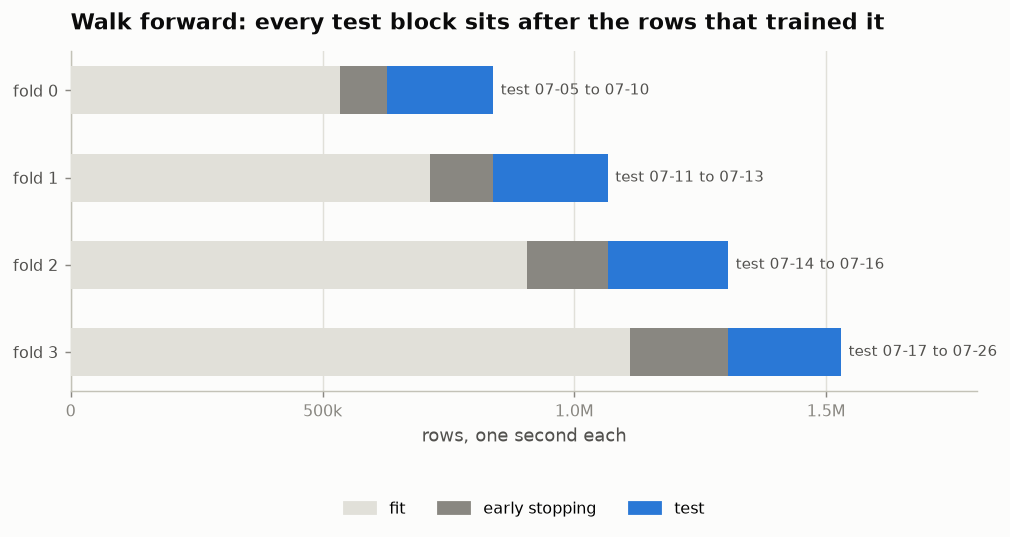

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.4))
for i, fold in enumerate(real["folds"]):
    y = len(real["folds"]) - 1 - i
    fit, val, test = fold["n_train"], fold["n_val"], fold["n_test"]
    ax.barh(y, fit, left=0, height=0.55, color=PALE, zorder=3)
    ax.barh(y, val, left=fit, height=0.55, color=MUTED, zorder=3)
    ax.barh(y, test, left=fit + val, height=0.55, color=BLUE, zorder=3)
    ax.text(fit + val + test + 15000, y,
            f"test {fold['test_dates'][0][5:]} to {fold['test_dates'][-1][5:]}",
            va="center", fontsize=8.5, color=INK2)
ax.set_yticks(range(len(real["folds"])))
ax.set_yticklabels([f"fold {i}" for i in reversed(range(len(real["folds"])))], color=INK2)
ax.set_xticks([0, 500_000, 1_000_000, 1_500_000])
ax.set_xticklabels(["0", "500k", "1.0M", "1.5M"])
ax.set_xlabel("rows, one second each")
ax.set_title("Walk forward: every test block sits after the rows that trained it")
ax.set_xlim(0, 1_800_000)
ax.grid(axis="x", zorder=0)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in (PALE, MUTED, BLUE)],
          ["fit", "early stopping", "test"],
          loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=3)
plt.show()

## 3. The headline

Three models on identical folds: a ridge on order-flow features only, a ridge on all 27,
and a gradient-boosted tree. The baseline they are scored against is the constant zero
forecast, so R2 here is "how much of the five-second move is explained that predicting
no-change would not have been".

The intervals are recomputed from the committed rows rather than read out of the record,
which is the point of publishing the rows at all.

In [6]:
pooled = {name: confidence_intervals(o) for name, o in
          read_oos(pl.read_parquet(DATA / "oos_real.parquet")).items()}

print(f"{'model':22s} {'R2 vs zero':>27s} {'hit rate':>25s}")
for name in ("ridge_ofi", "ridge_all", "gbt"):
    r2, hit = pooled[name]["r2_vs_zero"], pooled[name]["hit_rate"]
    print(f"{name:22s} {r2[0]:8.5f} [{r2[1]:7.5f}, {r2[2]:7.5f}] "
          f"{hit[0]:7.4f} [{hit[1]:6.4f}, {hit[2]:6.4f}]")

# What the record said, and what the rows say, have to be the same thing.
for name in ("ridge_ofi", "ridge_all", "gbt"):
    for metric in ("r2_vs_zero", "hit_rate"):
        assert np.allclose(pooled[name][metric], real["pooled"][name][metric], atol=1e-9), name
print("\nevery interval matches the published record exactly")

model                                   R2 vs zero                  hit rate
ridge_ofi               0.00070 [-0.09966, 0.04120]  0.7047 [0.6892, 0.7233]
ridge_all               0.03356 [-0.13461, 0.09921]  0.7352 [0.7150, 0.7585]
gbt                     0.10349 [0.09075, 0.11202]  0.7572 [0.7351, 0.7805]

every interval matches the published record exactly


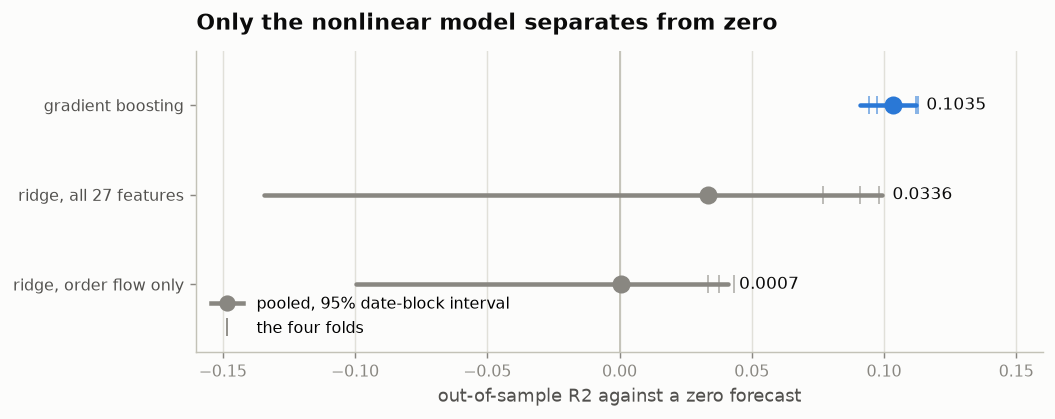

In [7]:
models = ["ridge_ofi", "ridge_all", "gbt"]
labels = ["ridge, order flow only", "ridge, all 27 features", "gradient boosting"]

fig, ax = plt.subplots(figsize=(8.4, 3))
for i, model in enumerate(models):
    color = BLUE if model == "gbt" else MUTED
    interval(ax, i, pooled[model]["r2_vs_zero"], color)
    folds = [f["metrics"][model]["r2_vs_zero"] for f in real["folds"]]
    ax.plot(folds, [i] * len(folds), "|", color=color, ms=10, alpha=0.6, zorder=4)
ax.axvline(0, color=AXIS, lw=1)
ax.set_yticks(range(len(models)))
ax.set_yticklabels(labels, color=INK2)
ax.set_xlabel("out-of-sample R2 against a zero forecast")
ax.set_title("Only the nonlinear model separates from zero")
ax.set_xlim(-0.16, 0.16)
ax.set_ylim(-0.75, 2.6)
ax.grid(axis="x", zorder=0)
ax.legend([plt.Line2D([], [], color=MUTED, marker="o", ms=8, lw=2.5),
           plt.Line2D([], [], color=MUTED, marker="|", ms=10, lw=0)],
          ["pooled, 95% date-block interval", "the four folds"], loc="lower left")
plt.show()

Two things are worth reading off that chart, and the second one matters more than the
first.

The gradient-boosted model reaches **R2 0.103** with a date-block interval that clears
zero comfortably, and its four folds sit in a tight band, so this is not one unusual week
carrying the average.

Both ridges have intervals that span zero and run deep into negative territory. Their
point estimates look respectable and mean very little: on a bad day a linear read of
order flow is worse than predicting nothing. The relationship the tree is finding is not
one a linear model recovers, which is itself informative about the microstructure.

## 4. The first thing that could be wrong: maybe Kraken is just slower

"A forecasts B" is exactly what you would also see if B were simply the thinner, slower
book, mechanically catching up to a price that was already public. That is a different
claim from "A discovers price", and distinguishing them needs the same experiment pointed
the other way.

So: same 20 days, same one-second bars, same feature builder, same folds, same model.
Only the direction changes. Kraken's book and flow are used to predict Coinbase's next
five seconds.

In [8]:
forward_r2 = confidence_intervals(rows("real"))["r2_vs_zero"]
backward_r2 = confidence_intervals(rows("reverse"))["r2_vs_zero"]

print(f"Coinbase to Kraken   R2 {forward_r2[0]:8.5f} [{forward_r2[1]:.5f}, {forward_r2[2]:.5f}]")
print(f"Kraken to Coinbase   R2 {backward_r2[0]:8.5f} [{backward_r2[1]:.5f}, {backward_r2[2]:.5f}]")
print(f"\nratio of point estimates: {forward_r2[0] / backward_r2[0]:.1f}x")

# The claim is the asymmetry, so the intervals must not touch.
assert backward_r2[2] < forward_r2[1], "the two directions' intervals overlap"
print(f"intervals are disjoint: reverse tops out at {backward_r2[2]:.5f}, "
      f"forward starts at {forward_r2[1]:.5f}")

Coinbase to Kraken   R2  0.10349 [0.09075, 0.11202]
Kraken to Coinbase   R2  0.01076 [0.00814, 0.01437]

ratio of point estimates: 9.6x
intervals are disjoint: reverse tops out at 0.01437, forward starts at 0.09075


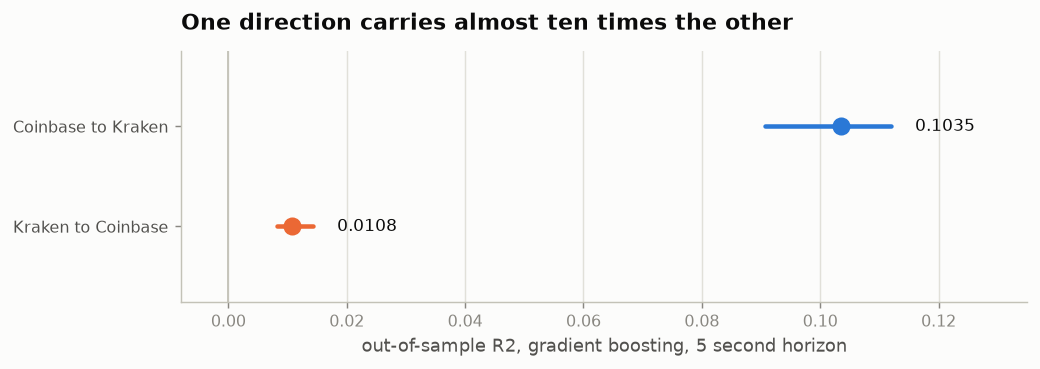

In [9]:
fig, ax = plt.subplots(figsize=(8.4, 2.5))
interval(ax, 1, forward_r2, BLUE)
interval(ax, 0, backward_r2, ORANGE)
ax.axvline(0, color=AXIS, lw=1)
ax.set_yticks([0, 1])
ax.set_yticklabels(["Kraken to Coinbase", "Coinbase to Kraken"], color=INK2)
ax.set_xlabel("out-of-sample R2, gradient boosting, 5 second horizon")
ax.set_title("One direction carries almost ten times the other")
ax.set_xlim(-0.008, 0.135)
ax.set_ylim(-0.75, 1.75)
ax.grid(axis="x", zorder=0)
plt.show()

The reverse direction is not zero, and it should not be: two venues trading the same asset
are mutually informative, and Kraken does lead sometimes. But it is roughly a tenth of the
forward direction, with intervals that do not come close to touching.

A symmetric mechanical relationship cannot produce that. Something asymmetric is happening,
and its direction is Coinbase to Kraken.

## 5. The second thing that could be wrong: leakage

Any forecasting pipeline can be made to look brilliant by accident. A feature computed
with a window that reaches one bar too far, a fold boundary off by one, a target that
shares a term with an input: all of them produce exactly the chart above.

The test that catches all of them at once is to break the target on purpose. The same
pipeline is rerun with the target **displaced by 3600 bars, one full hour, within each
day**. Every feature, every fold, every hyperparameter and every line of code is
unchanged. The model is now being asked to predict a return from an hour away, which
nothing in the input can know.

If any number survives that, the pipeline is leaking and nothing else in this notebook
means anything.

In [10]:
null_r2 = confidence_intervals(rows("placebo"))["r2_vs_zero"]
null_hit = confidence_intervals(rows("placebo"))["hit_rate"]

print(f"displaced target   R2 {null_r2[0]:8.5f} [{null_r2[1]:.5f}, {null_r2[2]:.5f}]")
print(f"                  hit {null_hit[0]:8.4f} [{null_hit[1]:.4f}, {null_hit[2]:.4f}]")

# The gate. Both have to come back indistinguishable from chance.
assert null_r2[1] < 0 < null_r2[2], f"placebo R2 interval misses zero: {null_r2}"
assert null_hit[1] < 0.52, "placebo hit rate is above the long-bias floor"
print("\nthe null holds: R2 straddles zero, hit rate sits at a coin flip")

displaced target   R2 -0.00010 [-0.00028, 0.00011]
                  hit   0.5035 [0.4958, 0.5124]

the null holds: R2 straddles zero, hit rate sits at a coin flip


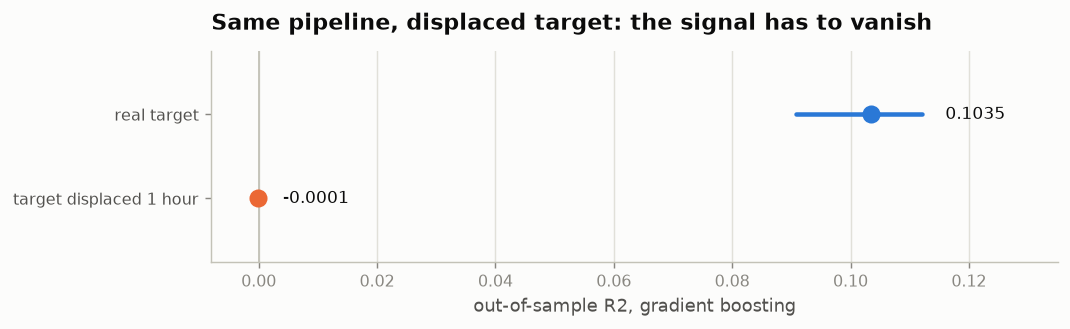

In [11]:
fig, ax = plt.subplots(figsize=(8.4, 2.1))
interval(ax, 1, forward_r2, BLUE)
interval(ax, 0, null_r2, ORANGE)
ax.axvline(0, color=AXIS, lw=1)
ax.set_yticks([0, 1])
ax.set_yticklabels(["target displaced 1 hour", "real target"], color=INK2)
ax.set_xlabel("out-of-sample R2, gradient boosting")
ax.set_title("Same pipeline, displaced target: the signal has to vanish")
ax.set_xlim(-0.008, 0.135)
ax.set_ylim(-0.75, 1.75)
ax.grid(axis="x", zorder=0)
plt.show()

## 6. Is the model honest about its own confidence?

R2 says the predictions covary with the outcome. It does not say the *magnitudes* are
right, and a model whose predictions are systematically twice the size of what actually
happens would still score well while being useless for sizing anything.

Binning the out-of-sample predictions into 20 equal-count buckets and plotting the mean
prediction in each against the mean realized return answers that directly.

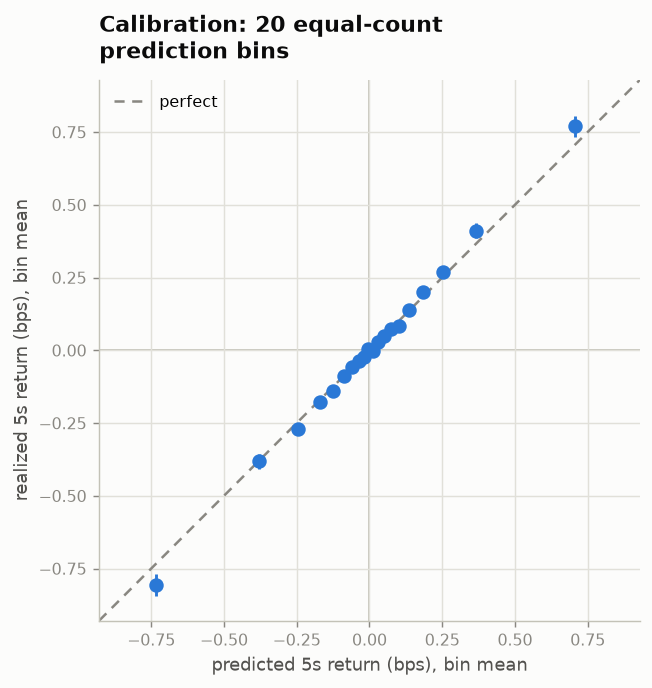

regression of realized on predicted, across bins: slope 1.083


In [12]:
o = rows("real")
edges = np.quantile(o.pred, np.linspace(0, 1, 21))
bucket = np.clip(np.digitize(o.pred, edges[1:-1]), 0, 19)
mean_pred = np.array([o.pred[bucket == b].mean() for b in range(20)])
mean_y = np.array([o.y[bucket == b].mean() for b in range(20)])
sem = np.array([o.y[bucket == b].std() / np.sqrt((bucket == b).sum()) for b in range(20)])
slope = float(np.polyfit(mean_pred, mean_y, 1)[0])

fig, ax = plt.subplots(figsize=(6, 5.4))
lim = max(abs(mean_pred).max(), abs(mean_y).max()) * 1.15
ax.plot([-lim, lim], [-lim, lim], color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=2, label="perfect")
ax.errorbar(mean_pred, mean_y, yerr=1.96 * sem, fmt="o", color=BLUE, ms=7, lw=1.6,
            capsize=0, zorder=4)
ax.axhline(0, color=AXIS, lw=1, zorder=1)
ax.axvline(0, color=AXIS, lw=1, zorder=1)
ax.set_xlabel("predicted 5s return (bps), bin mean")
ax.set_ylabel("realized 5s return (bps), bin mean")
ax.set_title("Calibration: 20 equal-count\nprediction bins")
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_aspect("equal")
ax.grid(zorder=0)
ax.legend(loc="upper left")
plt.show()

print(f"regression of realized on predicted, across bins: slope {slope:.3f}")

A slope near one means the model is neither timid nor overconfident: when it says half a
basis point, half a basis point is roughly what happens on average. The extreme buckets
sit slightly above the line, which is the mild conservatism you would want rather than the
failure mode you would not.

## 7. Where the signal actually lives

Average R2 over every bar hides the shape of the thing. What matters operationally is
whether the model knows *when* it knows.

Two definitions make that measurable. A move counts as real only if it exceeds **half the
prevailing spread** on the venue being predicted, which is the smallest move that could
pay for crossing it; anything smaller sits in a dead zone and is scored as no move.
Precision is then measured at a **forced traded share**: the model's threshold is set so
it calls exactly 2%, 5%, 10%, 25% or 50% of bars, and precision is measured there.

Forcing coverage is what makes the comparison against the null fair. A model calling 8% of
bars is answering an easier question than one calling 94%, so comparing them at whatever
coverage each happens to land on compares nothing.

In [13]:
spot = coverage_confidence_intervals(rows("real"), 0.02)["up_precision"]
published = real["selectivity"][0]["metrics"]["up_precision"]
assert np.allclose(spot, published, atol=1e-9)
print(f"recomputed precision at 2% coverage: {spot[0]:.4f} [{spot[1]:.4f}, {spot[2]:.4f}] "
      f"(matches the record)")

base = real["base_rates"]["up"]
null_base = placebo["base_rates"]["up"]
print(f"\n{'coverage':>9s} {'real':>25s} {'lift':>6s} {'displaced':>25s} {'lift':>6s}")
for s_real, s_null in zip(real["selectivity"], placebo["selectivity"]):
    r = s_real["metrics"]["up_precision"]
    n = s_null["metrics"]["up_precision"]
    print(f"{s_real['coverage']:>8.0%} {r[0]:7.4f} [{r[1]:.4f}, {r[2]:.4f}] {r[0] / base:5.1f}x "
          f"{n[0]:7.4f} [{n[1]:.4f}, {n[2]:.4f}] {n[0] / null_base:5.1f}x")
# Each run has its own base rate: displacing the target changes which bars cleared half a
# spread, so lift is measured against the run's own floor rather than a shared one.
print(f"\nbase rate, share of bars that rose more than half a spread:"
      f"  real {base:.4f}   displaced {null_base:.4f}")

recomputed precision at 2% coverage: 0.5257 [0.4873, 0.5707] (matches the record)

 coverage                      real   lift                 displaced   lift
      2%  0.5257 [0.4873, 0.5707]   5.2x  0.1403 [0.0862, 0.1770]   1.3x
      5%  0.4565 [0.4285, 0.4789]   4.5x  0.1456 [0.1097, 0.1637]   1.4x
     10%  0.3940 [0.3736, 0.4077]   3.9x  0.1439 [0.1176, 0.1587]   1.4x
     25%  0.3028 [0.2811, 0.3184]   3.0x  0.1215 [0.0942, 0.1464]   1.2x
     50%  0.2290 [0.2041, 0.2475]   2.2x  0.1075 [0.0852, 0.1287]   1.0x

base rate, share of bars that rose more than half a spread:  real 0.1019   displaced 0.1051


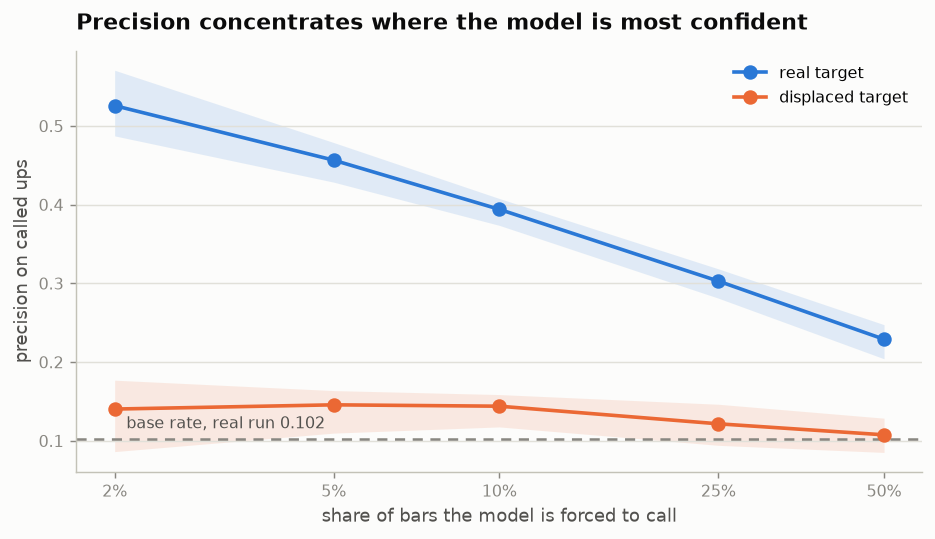

In [14]:
fig, ax = plt.subplots(figsize=(8.4, 4.2))
for rec, color, label in [(real, BLUE, "real target"), (placebo, ORANGE, "displaced target")]:
    cov = [s["coverage"] for s in rec["selectivity"]]
    band = np.array([s["metrics"]["up_precision"] for s in rec["selectivity"]])
    ax.fill_between(cov, band[:, 1], band[:, 2], color=color, alpha=0.13, lw=0)
    ax.plot(cov, band[:, 0], "-o", color=color, lw=2, ms=7, label=label, zorder=4)
ax.axhline(base, color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=2)
ax.text(0.021, base + 0.014, f"base rate, real run {base:.3f}", fontsize=9, color=INK2)
ax.set_xscale("log")
ax.minorticks_off()
ax.set_xticks([0.02, 0.05, 0.10, 0.25, 0.50])
ax.set_xticklabels(["2%", "5%", "10%", "25%", "50%"])
ax.set_xlabel("share of bars the model is forced to call")
ax.set_ylabel("precision on called ups")
ax.set_title("Precision concentrates where the model is most confident")
ax.grid(axis="y", zorder=0)
ax.legend(loc="upper right")
plt.show()

The real curve rises steeply as it is allowed to be more selective, from 2.2x the base
rate when forced to call half of all bars to **5.2x** on its most confident 2%. That
monotone shape is what a genuine ranking looks like.

The null curve sits between 1.0x and 1.4x with no trend across coverage, and that
flatness is the signature of no ranking at all: being allowed to be pickier buys it
nothing, because its ordering of the bars carries no information about direction.

It is worth being precise about why the null is not exactly 1.0x. The displaced model
still sits slightly above its own base rate, and that is not leakage. Volatility clusters,
so a model can learn to call more often when the book is active, and moves are larger
then. Predicting *when* something will happen is not predicting *which way*, and only the
second is worth anything here. Each run is measured against its own base rate, since
displacing the target changes which bars cleared half a spread.

## 8. A second measure that does not involve a model at all

Everything so far is a forecasting result, and forecasting results inherit the biases of
the model that produced them. The classical measure of price discovery does not fit a
model in the machine-learning sense at all: it fits a vector error-correction model to the
two venues' prices, then asks how much of the variance of the common permanent component
originates at each venue.

Hasbrouck's information share is the standard answer, and it comes as **bounds** rather
than a point, because when the venues' innovations are correlated the attribution is not
uniquely identified. The width of those bounds is itself the honest report of how much the
data can say.

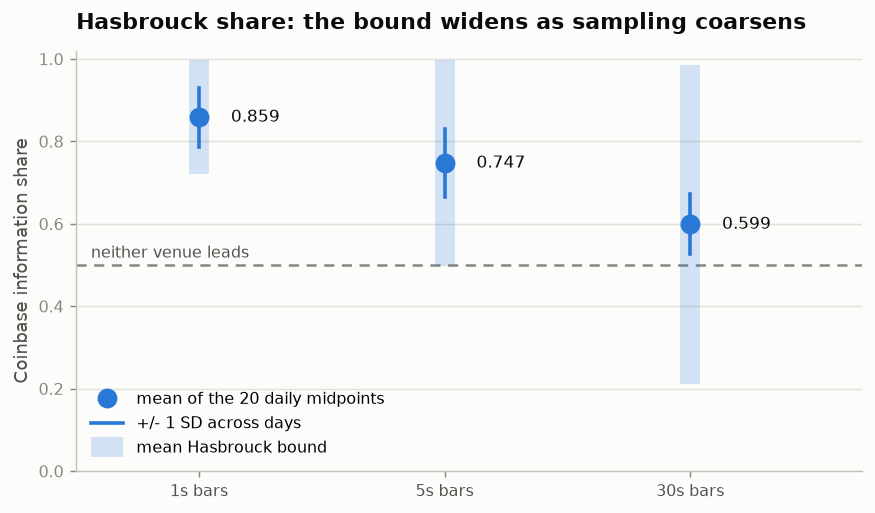

  1s bars: midpoint 0.8587 +/- 0.0714, mean bound width 0.2775, condition number 44,419
  5s bars: midpoint 0.7473 +/- 0.0824, mean bound width 0.4994, condition number 38,847
 30s bars: midpoint 0.5987 +/- 0.0725, mean bound width 0.7725, condition number 47,337


In [15]:
fig, ax = plt.subplots(figsize=(7.8, 4.2))
for i, block in enumerate(real["infoshare"]):
    bounds = np.array([e["bounds"][0] for e in block["estimates"]], dtype=float)
    mids = bounds.mean(axis=1)
    band = ax.plot([i, i], [bounds[:, 0].mean(), bounds[:, 1].mean()], color=BLUE, lw=11,
                   alpha=0.20, solid_capstyle="butt", zorder=3)[0]
    spread = ax.plot([i, i], [mids.mean() - mids.std(), mids.mean() + mids.std()],
                     color=BLUE, lw=2, zorder=4)[0]
    dot = ax.plot([i], [mids.mean()], "o", color=BLUE, ms=10, zorder=5)[0]
    ax.text(i + 0.13, mids.mean(), f"{mids.mean():.3f}", va="center", fontsize=9.5, color=INK)
ax.axhline(0.5, color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=2)
ax.text(-0.44, 0.518, "neither venue leads", fontsize=9, color=INK2)
ax.set_xticks(range(len(real["infoshare"])))
ax.set_xticklabels([f"{b['stride']}s bars" for b in real["infoshare"]], color=INK2)
ax.set_ylim(0, 1.02)
ax.set_xlim(-0.5, len(real["infoshare"]) - 0.3)
ax.set_ylabel("Coinbase information share")
ax.set_title("Hasbrouck share: the bound widens as sampling coarsens")
ax.grid(axis="y", zorder=0)
ax.legend([dot, spread, band],
          ["mean of the 20 daily midpoints", "+/- 1 SD across days", "mean Hasbrouck bound"],
          loc="lower left")
plt.show()

for block in real["infoshare"]:
    b = np.array([e["bounds"][0] for e in block["estimates"]], dtype=float)
    cond = np.array([e["conditioning"] for e in block["estimates"]], dtype=float)
    print(f"{block['stride']:>3d}s bars: midpoint {b.mean(axis=1).mean():.4f} "
          f"+/- {b.mean(axis=1).std():.4f}, mean bound width {(b[:, 1] - b[:, 0]).mean():.4f}, "
          f"condition number {cond.mean():,.0f}")

At one-second sampling Coinbase's share is **0.859**, well clear of the 0.5 that would mean
neither venue leads, and consistent across the 20 days. The agreement with the forecasting
result matters because the two measures share almost no machinery: one is a gradient-boosted
tree scored out of sample, the other is a linear cointegration model fit in sample.

The degradation with coarser sampling is expected rather than alarming. Sample every 30
seconds and both venues have long since reacted to anything that happened, so the
attribution collapses toward the residual correlation and the bounds open up to nearly the
whole interval. A share quoted without its sampling frequency is not an answer.

**One number from this analysis is deliberately not quoted.** Gonzalo-Granger component
shares are computed alongside the Hasbrouck bounds and left out of the writeup: under the
conditioning of this system they leave the unit interval on 6 of the 20 days, which is a
known failure mode when the error-correction matrix is near-singular. Hasbrouck bounds are
unaffected by that, so they are what gets reported.

## 9. What this does not claim

**It is not a trading result.** The R2 is a forecast of mid-price return. The
`gross_bps_per_trade` figure in the record is gross by name: no fees, no slippage, no queue
position, and no allowance for the difference between an edge measured on a captured tape
and an edge taken through a real order gateway at a real venue. A 0.2 bps gross edge does
not survive a 1 bps fee, and nothing here says it would.

**It is a measurement, not a law.** Twenty days, one instrument, two venues, one horizon.
Venue leadership is a function of fee schedules, market structure and where the flow
happens to be, all of which move.

**The staleness cut is a modelling choice.** Rows where either book had not updated within
five seconds are dropped, which removes 7.4% of bars. That is defensible, since a stale
book is not a price, and it is still a choice made by the analyst.

**The dead zone is defined by the spread, not by a cost model.** Half a spread is the
smallest move that could pay for crossing it, which is a lower bound on what would matter,
not an estimate of what would be profitable.

## 10. Everything, recomputed

The point of publishing the out-of-sample rows is that nothing here has to be taken on
faith. The cell below recomputes every headline number from the Parquet files and checks
each one against the published record. Executing this notebook is therefore a test: if any
number drifts, the notebook fails rather than quietly rendering a different result.

In [16]:
checks = []

for tag, rec in [("real", real), ("reverse", backward), ("placebo", placebo)]:
    pooled_tag = confidence_intervals(rows(tag))
    for metric in ("r2_vs_zero", "hit_rate", "gross_bps_per_trade"):
        got, want = pooled_tag[metric], rec["pooled"]["gbt"][metric]
        ok = np.allclose(got, want, atol=1e-9, equal_nan=True)
        checks.append(ok)
        print(f"{tag:8s} {metric:20s} {got[0]:9.5f} [{got[1]:8.5f}, {got[2]:8.5f}]  "
              f"{'matches record' if ok else 'DIFFERS'}")

classes = class_confidence_intervals(rows("real"))
for metric in ("up_precision", "down_precision"):
    got, want = classes[metric], real["classes"]["gbt"][metric]
    ok = np.allclose(got, want, atol=1e-9)
    checks.append(ok)
    print(f"{'real':8s} {metric:20s} {got[0]:9.5f} [{got[1]:8.5f}, {got[2]:8.5f}]  "
          f"{'matches record' if ok else 'DIFFERS'}")

assert all(checks), "a published number does not reproduce from the published rows"
print(f"\n{len(checks)} published numbers recomputed from the rows, all matching")

real     r2_vs_zero             0.10349 [ 0.09075,  0.11202]  matches record
real     hit_rate               0.75719 [ 0.73511,  0.78052]  matches record
real     gross_bps_per_trade    0.20024 [ 0.15078,  0.24480]  matches record


reverse  r2_vs_zero             0.01076 [ 0.00814,  0.01437]  matches record
reverse  hit_rate               0.58163 [ 0.56915,  0.59704]  matches record
reverse  gross_bps_per_trade    0.09110 [ 0.07484,  0.10704]  matches record
placebo  r2_vs_zero            -0.00010 [-0.00028,  0.00011]  matches record
placebo  hit_rate               0.50352 [ 0.49580,  0.51244]  matches record
placebo  gross_bps_per_trade   -0.00088 [-0.00379,  0.00231]  matches record


real     up_precision           0.16165 [ 0.13223,  0.18758]  matches record
real     down_precision         0.15363 [ 0.12165,  0.18260]  matches record

11 published numbers recomputed from the rows, all matching


---

**Data and code.** The predictions and run records in `data/` were exported from
[crosstick](https://github.com/ryanp2718/crosstick) at commit `fb7a22d`, which is also the
commit this notebook installs its analysis code from. The platform side of the story, an
ingest-to-lake pipeline for three exchanges with reconstructed order books and a
cross-exchange NBBO, lives there.